# Week 6 – Applied Computer Vision in Your Own Domain
## Solar-panel condition classification (7 classes) with ResNet-18

**Course:** Introduction to Applied AI (Project 2) &nbsp;|&nbsp; **Dataset:** *Solar Panel Images* (Kaggle, `pythonafroz/solar-panel-images`) &nbsp;|&nbsp; **Platform:** Kaggle Notebook (this run used **CPU**)

### Key numbers from this run (all values come from the saved cell outputs)

| Stage | Value |
|---|---|
| Images indexed | 885 in 7 folders (one image = one group) |
| Imbalance ratio (raw) | 193 / 16 = **12.1** |
| Exact duplicates | **165 files** in **74 identical sets** → **91 extra copies removed** → **794** images |
| Imbalance ratio (after de-dup) | 186 / 16 = **11.6** |
| Split (group-aware, stratified) | train **551** / val **133** / test **110** |
| Near-duplicates (train ↔ eval) | test **12 / 110 (10.9 %)**, val **20 / 133 (15.0 %)** → removed → val **113**, test **98** |
| Class weights $N/(K\,n_c)$ | 0.605 (Clean) … **7.871 (New)** |
| Backbone | ResNet-18, **random init** (no ImageNet weights were available) – 11,180,103 trainable parameters |
| Best validation macro-F1 | **0.477** (epoch 10 of 15) |
| **Test macro-F1** (used once) | **0.432**; accuracy **0.510** (50 / 98); weighted-F1 0.524 |
| Weakest class | **New** (recall 0/3, F1 = 0.000), then Physical-Damage (F1 0.182) |
| Grad-CAM verdict | **Shortcut suspected** (sky / background / watermarks) – not confirmed |

> **How to read this notebook.** Every original code cell is unchanged. I added (1) a **heading + explanation + equations** cell *before* each code cell, and (2) a **results + calculations** cell *after* it that uses the real numbers printed by that cell. The orange **"Write it"** cells answer the lab's written questions.

---
# Part 0 – Configuration cell

**What it does.** This is the *only* cell that changes between datasets; every later cell reads these variables.

| Setting | Value used | Why |
|---|---|---|
| `DATA_ROOT` / `TRAIN_DIR` | `/kaggle/input/datasets/pythonafroz/solar-panel-images` | Folder that (recursively) contains the 7 class folders (`Faulty_solar_panel/<class>/`). |
| `TEST_DIR` | `None` | The dataset has no test folder → Part 2 **carves a grouped test set** from the training data. |
| `GRAYSCALE` | `False` | Colour is evidence here: dust is brown/grey, snow is white, bird-drop is white/brown, electrical damage shows burn colours. |
| `IMG_SIZE` | 224 | Native input of ImageNet backbones; compute ∝ side² (448 would cost ≈ 4×). |
| `BACKBONE` | `resnet18` | Fast baseline (11.7 M parameters). |
| `GROUP_PATTERN` | `None` | File names (`Bird (1).jpeg`, `Dust (25).jpg` …) contain **no** subject id → every image is its own group. |
| `BINARY`, `POSITIVE`, `TARGET_RECALL` | `False`, `None`, 0.95 | 7-class task → the threshold/PPV analysis of Part 5 is replaced by **per-class** recall/specificity. |

**Classes (K = 7):** Bird-drop, Clean, Dusty, Electrical-damage, New, Physical-Damage, Snow-Covered.

In [1]:
# ============ CHANGE ONLY THIS CELL FOR YOUR OWN DATASET ============
DATA_ROOT = '/kaggle/input/datasets/pythonafroz/solar-panel-images'   # folder that holds the class folders
TRAIN_DIR = DATA_ROOT        # folder whose subfolders are the class folders (Bird-drop, Clean, Dusty, Electrical-damage, New, Physical-Damage, Snow-Covered)
TEST_DIR = None              # no separate test folder -> the code carves a test set
GRAYSCALE = False            # solar-panel photos are colour: colour helps (dust, snow, bird-drop)
IMG_SIZE = 224
BACKBONE = 'resnet18'
# File names carry no group / subject id, so no grouping is possible -> every image is its own group.
GROUP_PATTERN = None
BINARY = False               # 7-class task: every folder stays its own class (no merging)
NORMAL_KEYWORD = None        # only used when BINARY = True
NORMAL_LABEL = None          # only used when BINARY = True
POSITIVE = None              # only used when BINARY = True (no 'positive' class here)
TARGET_RECALL = 0.95         # only used when BINARY = True
# ======================================================================

---
# Setup – Imports, seeds and device

Imports NumPy/Pandas (tables), PIL (images), PyTorch/torchvision (model), scikit-learn (splits and metrics).
Seeds `torch.manual_seed(42)` and `np.random.seed(42)` make runs repeatable.

In [2]:
import os
import re
import time
import copy
import hashlib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score,
                             roc_auc_score, roc_curve)

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cpu


**Output reading.** `Device: cpu` → no GPU was attached. This explains the slow training in Part 4 (≈ **76 s per epoch**). On a T4 GPU the same epoch typically takes a few seconds. *Fix:* Kaggle → Settings → Accelerator → GPU T4.

---
# Part 1 – Index and audit the dataset

## Task 1.1 – One row per image, class counts, imbalance ratio

**What it does.** Walks the folders, builds a table with one row per image (`path`, `label`, `orig_class`, `file`, `group`). Because `GROUP_PATTERN = None`, the group id is the **full path**, so each image is its own group (file names such as `Bird (1)` repeat across class folders, so the path – not the name – must be the key).

**Equations used**

$$\text{Imbalance ratio}=\frac{n_{\max}}{n_{\min}}\qquad\qquad \text{Images per group}=\frac{N_{\text{images}}}{N_{\text{groups}}}$$

In [3]:
IMG_EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.webp')

def find_class_dirs(folder):
    """Return every sub-folder that directly contains images (= a class folder).
    Works whether the class folders sit directly in `folder` or one/two levels deeper
    (e.g. Kaggle's  <dataset>/<subfolder>/<class>/...)."""
    if not os.path.isdir(folder):
        raise FileNotFoundError(
            f'{folder} does not exist. Attach the dataset via "Add Input" in the Kaggle '
            f'sidebar, then copy its real path and set DATA_ROOT in the config cell.')
    dirs = []
    for root, subdirs, files in os.walk(folder):
        if any(f.lower().endswith(IMG_EXT) for f in files):
            dirs.append(root)
    if not dirs:
        raise FileNotFoundError(
            f'No images found under {folder}. Contents: {os.listdir(folder)[:10]}. '
            f'Set DATA_ROOT/TRAIN_DIR to the folder that holds the class folders.')
    return sorted(dirs)

def index_folder(folder):
    """One row per image: path, label, original class folder, file name, group id."""
    rows = []
    for cdir in find_class_dirs(folder):
        cls = os.path.basename(cdir)
        for f in sorted(os.listdir(cdir)):
            if f.lower().endswith(IMG_EXT):
                if BINARY:
                    label = NORMAL_LABEL if NORMAL_KEYWORD in cls.lower() else POSITIVE
                else:
                    label = cls                      # multi-class: folder name = class
                rows.append({'path': os.path.join(cdir, f), 'label': label,
                             'orig_class': cls, 'file': f})
    df = pd.DataFrame(rows)
    if df.empty:
        raise FileNotFoundError(f'No images with extensions {IMG_EXT} found under {folder}.')
    found = df['label'].unique().tolist()
    if len(found) < 2:
        raise ValueError(f'Only one class found {found}. For a multi-class dataset set '
                         f'BINARY = False in the config cell.')
    if GROUP_PATTERN:
        m = df['file'].str.extract(GROUP_PATTERN, expand=False)
        df['group'] = m.fillna(df['path'])          # no match: its own group
    else:
        df['group'] = df['path']                    # file names repeat across class folders -> use the full path
    return df

train_df = index_folder(TRAIN_DIR)
test_df = index_folder(TEST_DIR) if TEST_DIR else None
classes = sorted(train_df['label'].unique())

counts = train_df['label'].value_counts().reindex(classes)
print(f'{len(classes)} classes found: {classes}')
print(counts.to_string())
print(f'Imbalance ratio (max / min): {counts.max() / counts.min():.1f}')
print(f'Images per group: {len(train_df) / train_df.group.nunique():.2f}')
print('\nOriginal class folders:')
print(train_df['orig_class'].value_counts().to_string())
print('\nGroup regex check:')
print(train_df[['file', 'group']].head(10).to_string())

7 classes found: ['Bird-drop', 'Clean', 'Dusty', 'Electrical-damage', 'New', 'Physical-Damage', 'Snow-Covered']
label
Bird-drop            191
Clean                193
Dusty                190
Electrical-damage    103
New                   16
Physical-Damage       69
Snow-Covered         123
Imbalance ratio (max / min): 12.1
Images per group: 1.00

Original class folders:
orig_class
Clean                193
Bird-drop            191
Dusty                190
Snow-Covered         123
Electrical-damage    103
Physical-Damage       69
New                   16

Group regex check:
             file                                                                                              group
0   Bird (1).jpeg   /kaggle/input/datasets/pythonafroz/solar-panel-images/Faulty_solar_panel/Bird-drop/Bird (1).jpeg
1   Bird (10).jpg   /kaggle/input/datasets/pythonafroz/solar-panel-images/Faulty_solar_panel/Bird-drop/Bird (10).jpg
2  Bird (100).jpg  /kaggle/input/datasets/pythonafroz/solar-panel-im

### Results and calculations

| Class | Images | Share of 885 |
|---|---|---|
| Clean | 193 | 21.8 % |
| Bird-drop | 191 | 21.6 % |
| Dusty | 190 | 21.5 % |
| Snow-Covered | 123 | 13.9 % |
| Electrical-damage | 103 | 11.6 % |
| Physical-Damage | 69 | 7.8 % |
| **New** | **16** | **1.8 %** |
| **Total** | **885** | 100 % |

$$\text{Imbalance ratio}=\frac{193}{16}=12.06\approx \mathbf{12.1}\qquad\qquad \text{Images per group}=\frac{885}{885}=\mathbf{1.00}$$

* **Imbalance 12.1 : 1** is above the ~10 : 1 range where weighted loss alone is comfortable (slide 18) → class weights **and** a macro metric are needed.
* **1.00 image per group** → the regex check printed `group = full path` for every row. There is **no way to group by panel/site** from file names, so a random split cannot be made patient-safe. This is exactly why the near-duplicate audit in Part 2 matters.
* The accuracy of a classifier that always says "Clean" would be only $193/885 = 21.8\%$; chance level for 7 classes is $1/7=14.3\%$.

## Task 1.2 – What do the images look like?

**What it does.** Reads the header of 300 random images to report width, height and colour mode, then draws 5 random images per class (7 × 5 grid) so you can eyeball differences that are *not* the thing you want the model to learn.

          w       h
min   149.0   110.0
50%   720.0   600.0
max  5472.0  5376.0
Colour modes: {'RGB': 291, 'RGBA': 9}


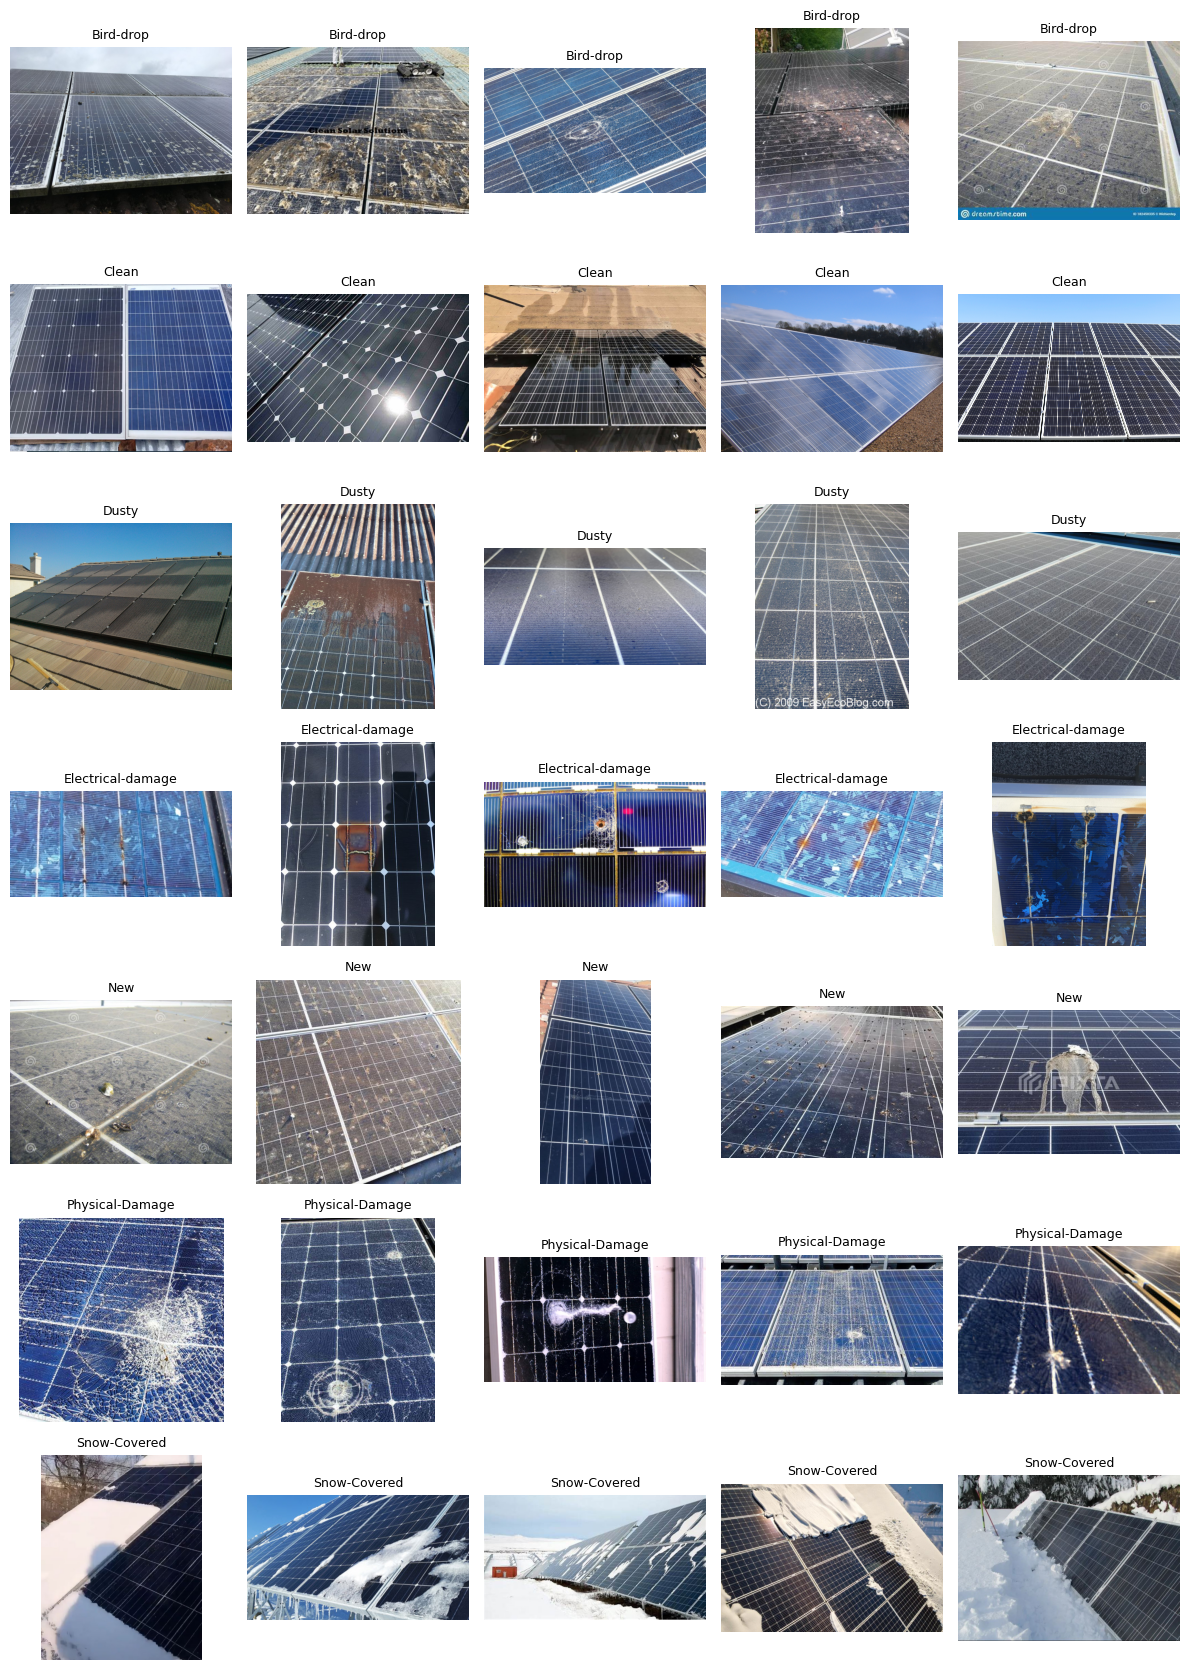

In [4]:
sample = train_df.sample(min(300, len(train_df)), random_state=0)
info = []
for p in sample['path']:
    with Image.open(p) as im:
        info.append({'w': im.size[0], 'h': im.size[1], 'mode': im.mode})
info = pd.DataFrame(info)
print(info.describe().round(0).loc[['min', '50%', 'max']])
print('Colour modes:', info['mode'].value_counts().to_dict())

fig, axes = plt.subplots(len(classes), 5, figsize=(12, 2.4 * len(classes)))
axes = np.atleast_2d(axes)
for r, c in enumerate(classes):
    pool = train_df[train_df.label == c]['path']
    paths = pool.sample(min(5, len(pool)), random_state=1)
    for ax, p in zip(axes[r], paths):
        ax.imshow(Image.open(p).convert('RGB'))
        ax.set_title(c, fontsize=9)
        ax.axis('off')
    for ax in axes[r][len(paths):]:
        ax.axis('off')
plt.tight_layout()
plt.show()

### Results and calculations

| | width (px) | height (px) |
|---|---|---|
| min | 149 | 110 |
| median | 720 | 600 |
| max | 5,472 | 5,376 |

* **Colour modes:** `{'RGB': 291, 'RGBA': 9}` → $291/300=97\%$ RGB and $9/300 = 3\%$ RGBA (transparent channel). The loader calls `.convert('RGB')`, which drops the alpha channel safely.
* **Size spread:** the largest image has $5472\times5376 \approx 29.4$ M pixels and the smallest $149\times110=16{,}390$ px → a ratio of ≈ **1,800 : 1**. Everything is resized to $224\times224=50{,}176$ px, so small images are **up-sampled** (blurry) and large ones **down-sampled** (fine detail such as small cracks can vanish).

> ### ✍️ Write it – Part 1
> **Counts / ratio:** Clean 193, Bird-drop 191, Dusty 190, Snow-Covered 123, Electrical-damage 103, Physical-Damage 69, New 16 → imbalance ratio 193/16 = **12.1**.
> **Colour and size:** colour photos (291 RGB + 9 RGBA of 300 sampled), median ≈ 720 × 600, range 149 × 110 to 5472 × 5376.
> **First shortcut suspects (from the sample grid):**
> 1. **Watermarks / stock-photo logos** (e.g. *dreamstime*, *EasyEcoBlog*, *DIXTA*, *shutterstock*) appear on some images, and they are not distributed evenly over classes → the model could learn "logo ⇒ class".
> 2. **Background/scene:** *Clean* images often show blue sky and horizon, *Snow-Covered* images are dominated by white ground, and *Dusty* images are often wide roof shots. Scene context ≠ panel condition.
> 3. **Label noise in `New`:** several sampled "New" panels visibly carry dirt/droppings, so the label is questionable, and with only 16 images the class is also tiny.

## Task 1.3 – Group sanity check

**What it does.** Counts how many groups contain more than one image (`g > 1`). If the regex had worked on a real subject id, several images would share a group.

$$\#\{\text{groups with }>1\text{ image}\}=0\ \Rightarrow\ N_{\text{groups}}=N_{\text{images}}$$

In [5]:
g = train_df.groupby('group').size().sort_values(ascending=False)
print('Groups with more than 1 image:', (g > 1).sum())
print(g.head(10).to_string())
print(train_df[train_df['group'] == g.index[0]][['orig_class', 'file']].to_string())

Groups with more than 1 image: 0
group
/kaggle/input/datasets/pythonafroz/solar-panel-images/Faulty_solar_panel/Snow-Covered/Snow (99).jpg    1
/kaggle/input/datasets/pythonafroz/solar-panel-images/Faulty_solar_panel/Bird-drop/Bird (1).jpeg       1
/kaggle/input/datasets/pythonafroz/solar-panel-images/Faulty_solar_panel/Bird-drop/Bird (10).jpg       1
/kaggle/input/datasets/pythonafroz/solar-panel-images/Faulty_solar_panel/Bird-drop/Bird (100).jpg      1
/kaggle/input/datasets/pythonafroz/solar-panel-images/Faulty_solar_panel/Bird-drop/Bird (101).jpg      1
/kaggle/input/datasets/pythonafroz/solar-panel-images/Faulty_solar_panel/Snow-Covered/Snow (84).jpg    1
/kaggle/input/datasets/pythonafroz/solar-panel-images/Faulty_solar_panel/Snow-Covered/Snow (83).jpg    1
/kaggle/input/datasets/pythonafroz/solar-panel-images/Faulty_solar_panel/Snow-Covered/Snow (82).JPG    1
/kaggle/input/datasets/pythonafroz/solar-panel-images/Faulty_solar_panel/Snow-Covered/Snow (81).JPG    1
/kaggle/input/da

**Result.** `Groups with more than 1 image: 0`; the biggest group has size 1 (e.g. `Snow (99).jpg`). This confirms the dataset offers **no subject/panel id**. A "group split" therefore only guarantees that the same *file* is not on both sides; **it cannot catch the same panel photographed twice or the same photo saved under two names** – that is why Part 2 adds MD5 and fingerprint checks.

---
# Part 2 – Leakage audit

## Task 2.1 – Exact duplicates (MD5)

**Idea.** Two files can only be byte-identical if they have the **same size**, so only files whose size occurs more than once are hashed (much faster than reading all images). Hashing is done with 8 threads.

$$\text{MD5}(a)=\text{MD5}(b)\ \Rightarrow\ a \text{ and } b \text{ are byte-identical}$$

$$\text{extra copies}=\underbrace{\#\text{duplicate files}}_{165}-\underbrace{\#\text{identical sets}}_{74}$$

In [6]:
from concurrent.futures import ThreadPoolExecutor

def md5(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(chunk), b''):   # stream, never load whole file
            h.update(block)
    return h.hexdigest()

def fingerprint(path, n=32):
    """32 x 32 grayscale thumbnail, standardized: robust to resizing,
    recompression, and brightness changes."""
    with Image.open(path) as im:
        im.draft('L', (n * 4, n * 4))            # fast JPEG decode
        a = np.asarray(im.convert('L').resize((n, n)), dtype=np.float32)
    return ((a - a.mean()) / (a.std() + 1e-6)).flatten()

all_df = pd.concat([train_df.assign(split='train'),
                    test_df.assign(split='test')]) if TEST_DIR else train_df.copy()
all_df = all_df.reset_index(drop=True)

# Speed-up: two files can only be byte-identical if they have the same size,
# so only hash files whose size occurs more than once (instead of reading every image).
t0 = time.time()
all_df['size'] = [os.path.getsize(p) for p in all_df['path']]
need = all_df.duplicated('size', keep=False)
print(f'{need.sum()} of {len(all_df)} files share a size with another file -> hashing only those')

all_df['md5'] = all_df['path']                   # unique placeholder = "not a duplicate"
with ThreadPoolExecutor(max_workers=8) as ex:    # reading files is I/O bound -> threads help
    all_df.loc[need, 'md5'] = list(ex.map(md5, all_df.loc[need, 'path']))
print(f'Hashing done in {time.time() - t0:.0f}s')

exact = all_df[all_df.duplicated('md5', keep=False)]
print('Exact duplicate files:', len(exact))
print('Duplicate groups (sets of identical files):', exact['md5'].nunique())
if len(exact):
    print(exact.sort_values('md5')[['orig_class', 'file', 'md5']].head(20).to_string())
    conflict = exact.groupby('md5')['label'].nunique()
    print('Identical files with DIFFERENT labels:', (conflict > 1).sum())

169 of 885 files share a size with another file -> hashing only those
Hashing done in 1s
Exact duplicate files: 165
Duplicate groups (sets of identical files): 74
            orig_class                 file                               md5
68           Bird-drop       Bird (168).jpg  03fe473544629041104b1cdf123426a8
12           Bird-drop        Bird (11).jpg  03fe473544629041104b1cdf123426a8
38           Bird-drop       Bird (133).jpg  03fe473544629041104b1cdf123426a8
93           Bird-drop       Bird (190).jpg  0862a9ece39a48c8950b613c903f5e3f
97           Bird-drop       Bird (194).jpg  0862a9ece39a48c8950b613c903f5e3f
758    Physical-Damage    Physical (69).jpg  0cd17ef0f5c566ede3831d5dbc544ffd
699    Physical-Damage    Physical (15).jpg  0cd17ef0f5c566ede3831d5dbc544ffd
244              Clean      Clean (132).jpg  102ddad325d4321d0074b2525e66d8c8
305              Clean      Clean (188).jpg  102ddad325d4321d0074b2525e66d8c8
508              Dusty        Dust (25).jpg  15e16078c30e

### Results and calculations

| Quantity | Value | Calculation |
|---|---|---|
| Files sharing a size with another file | 169 of 885 | 169 / 885 = **19.1 %** (only these were hashed, in 1 s) |
| Exact duplicate files | **165** | 165 / 885 = **18.6 %** of the dataset |
| Identical sets | **74** | average set size 165 / 74 = **2.23** files |
| Redundant copies | **91** | 165 − 74 = 91 → 91 / 885 = **10.3 %** |
| Same size but *different* bytes | 4 files | 169 − 165 = 4 (hash separated them correctly) |
| Identical files with **different labels** | **2 sets** | the same photo is filed in two classes → a **label conflict** |

Example: `Bird (168).jpg`, `Bird (11).jpg`, `Bird (133).jpg` share MD5 `03fe4735…` (3 copies of one picture).

**Why this matters.** If one copy lands in train and another in test, the model is graded on a picture it has memorised, which inflates the test score.

## Task 2.2 – Remove exact duplicates (keep one copy)

**What it does.** Maps each path to its MD5 and keeps the first file of every identical set (`drop_duplicates('md5', keep='first')`).

$$N_{\text{after}}=N_{\text{before}}-\text{extra copies}=885-91=794$$

In [7]:
# Keep one copy of each byte-identical file
train_df['md5'] = train_df['path'].map(dict(zip(all_df['path'], all_df['md5'])))
before = len(train_df)
train_df = train_df.drop_duplicates('md5', keep='first').reset_index(drop=True)
print(f'Removed {before - len(train_df)} duplicate copies; {len(train_df)} images remain')
print(train_df['label'].value_counts().to_string())

Removed 91 duplicate copies; 794 images remain
label
Clean                186
Dusty                182
Bird-drop            143
Snow-Covered         113
Electrical-damage     91
Physical-Damage       63
New                   16


### Results and calculations

| Class | Before | After | Removed | % removed |
|---|---|---|---|---|
| Bird-drop | 191 | 143 | 48 | 25.1 % |
| Clean | 193 | 186 | 7 | 3.6 % |
| Dusty | 190 | 182 | 8 | 4.2 % |
| Snow-Covered | 123 | 113 | 10 | 8.1 % |
| Electrical-damage | 103 | 91 | 12 | 11.7 % |
| Physical-Damage | 69 | 63 | 6 | 8.7 % |
| New | 16 | 16 | 0 | 0 % |
| **Total** | **885** | **794** | **91** | **10.3 %** |

* Check: 48 + 7 + 8 + 10 + 12 + 6 + 0 = **91** ✔.
* **Bird-drop lost a quarter of its images** (48 of 191) – it was by far the most duplicated class, so any earlier "good" score on Bird-drop would have been partly memorisation.
* New imbalance ratio: $186/16 = 11.6$ (down from 12.1).
* ⚠️ `keep='first'` is arbitrary for the **2 label-conflict sets**: the surviving label depends on file order. A cleaner choice is to drop both copies of a conflicting image.

## Task 2.3 – Stratified group split (train / val / test)

**What it does.** `StratifiedGroupKFold(n_splits=6)` keeps **groups intact** and **class proportions similar**. The first fold becomes validation ($\approx 1/6$). The remaining data are split again to carve a test set ($\approx 1/6$ of the rest).

$$N_{\text{val}}\approx\frac{794}{6}=132.3,\qquad N_{\text{test}}\approx\frac{794-133}{6}=\frac{661}{6}=110.2,\qquad N_{\text{train}}=661-110$$

In [8]:
# Validation split BY GROUP: no group (here: no single image) appears in both train and val
sgkf = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
tr_idx, va_idx = next(sgkf.split(train_df, train_df['label'],
                                 train_df['group']))
tr_df = train_df.iloc[tr_idx].reset_index(drop=True)
va_df = train_df.iloc[va_idx].reset_index(drop=True)
if not TEST_DIR:                                         # carve a grouped test set
    tr_idx, te_idx = next(sgkf.split(tr_df, tr_df['label'], tr_df['group']))
    tr_df, test_df = (tr_df.iloc[tr_idx].reset_index(drop=True),
                      tr_df.iloc[te_idx].reset_index(drop=True))

shared = set(tr_df.group) & set(va_df.group)
print(f'train {len(tr_df)} | val {len(va_df)} | test {len(test_df)}')
print('Groups shared by train and val:', len(shared))   # must be 0
print('Groups shared by train and test:', len(set(tr_df.group) & set(test_df.group)))
print(va_df['label'].value_counts().to_string())

train 551 | val 133 | test 110
Groups shared by train and val: 0
Groups shared by train and test: 0
label
Clean                31
Dusty                30
Bird-drop            24
Snow-Covered         19
Electrical-damage    16
Physical-Damage      10
New                   3


### Results and calculations

* **train 551 | val 133 | test 110** → 551 + 133 + 110 = **794** ✔ (69.4 % / 16.8 % / 13.9 %).
* **Groups shared by train and val = 0** and **by train and test = 0** ✔ (required by the lab).
* Validation class counts: Clean 31, Dusty 30, Bird-drop 24, Snow-Covered 19, Electrical-damage 16, Physical-Damage 10, **New 3** → total $31+30+24+19+16+10+3=133$ ✔.
* ⚠️ **Only 3 `New` images** in validation (and later 3 in test): one image changes that class's recall by 33 points. Any score on `New` is statistical noise.
* Because every image is its own group, "0 shared groups" **does not prove** there is no leakage → see the fingerprint check next.

## Task 2.4 – Near-duplicates between the splits (fingerprints)

**Method (slide 13).** Shrink each image to $32\times32$ grayscale, standardise it, and compare images by the mean absolute difference:

$$z=\frac{a-\bar a}{\sigma_a},\qquad d(i,j)=\frac{1}{1024}\sum_{p=1}^{1024}\bigl|z_{i,p}-z_{j,p}\bigr|,\qquad d<0.10\Rightarrow\text{near-duplicate}$$

Reference values from the lab: re-compressed copy ≈ **0.007**; genuinely different image ≥ **0.12**. For every val/test image the code finds its nearest *train* image (`torch.cdist` with $p=1$, divided by 1024), shows the 6 closest test↔train pairs **before deleting anything**, and then drops flagged val/test images.

Fingerprints done in 35s
Test images with a near-duplicate in train: 12 of 110
Val images with a near-duplicate in train:  20 of 133
Closest test distances: [0.005 0.008 0.008 0.01  0.014 0.014 0.018 0.019 0.023 0.025]


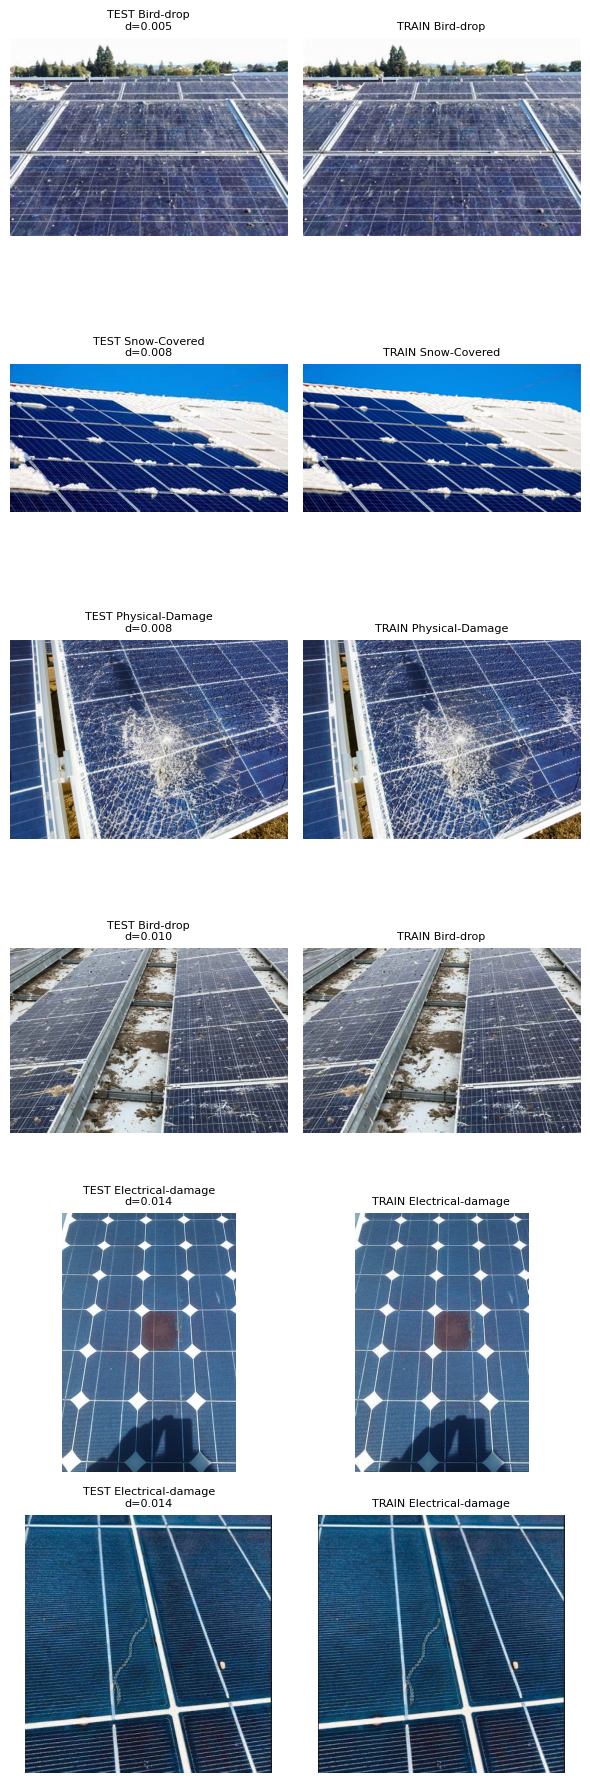

After removal: train 551 | val 113 | test 98
Val labels: {'Clean': 30, 'Dusty': 30, 'Bird-drop': 16, 'Snow-Covered': 16, 'Electrical-damage': 12, 'Physical-Damage': 6, 'New': 3} | Test labels: {'Dusty': 25, 'Clean': 23, 'Bird-drop': 16, 'Snow-Covered': 13, 'Electrical-damage': 11, 'Physical-Damage': 7, 'New': 3}


In [9]:
# Near-duplicate check between the carved splits (needed because TEST_DIR = None)
def fp_matrix(df):
    return torch.tensor(np.stack([fingerprint(p) for p in df['path']]),
                        dtype=torch.float32, device=device)

def nearest(A, B, chunk=512):
    """For each row of A: mean absolute difference to its closest row of B, and that row's index."""
    dists, idxs = [], []
    for i in range(0, len(A), chunk):
        d = torch.cdist(A[i:i + chunk], B, p=1) / A.shape[1]
        m, j = d.min(1)
        dists.append(m.cpu())
        idxs.append(j.cpu())
    return torch.cat(dists).numpy(), torch.cat(idxs).numpy()

t0 = time.time()
FP_tr, FP_va, FP_te = fp_matrix(tr_df), fp_matrix(va_df), fp_matrix(test_df)
print(f'Fingerprints done in {time.time() - t0:.0f}s')

d_te, j_te = nearest(FP_te, FP_tr)
d_va, j_va = nearest(FP_va, FP_tr)
near_te, near_va = d_te < 0.10, d_va < 0.10
print(f'Test images with a near-duplicate in train: {near_te.sum()} of {len(test_df)}')
print(f'Val images with a near-duplicate in train:  {near_va.sum()} of {len(va_df)}')
print('Closest test distances:', np.sort(d_te)[:10].round(3))

# Inspect the closest pairs BEFORE deleting anything
order = np.argsort(d_te)[:6]
fig, axes = plt.subplots(len(order), 2, figsize=(6, 3 * len(order)))
for r, k in enumerate(order):
    a, b = test_df.iloc[k], tr_df.iloc[j_te[k]]
    axes[r, 0].imshow(Image.open(a['path']).convert('RGB'))
    axes[r, 0].set_title(f"TEST {a['orig_class']}\nd={d_te[k]:.3f}", fontsize=8)
    axes[r, 1].imshow(Image.open(b['path']).convert('RGB'))
    axes[r, 1].set_title(f"TRAIN {b['orig_class']}", fontsize=8)
    axes[r, 0].axis('off')
    axes[r, 1].axis('off')
plt.tight_layout()
plt.show()
# Remove val/test images that have a near-duplicate in train (they would inflate the scores)
test_df = test_df[~near_te].reset_index(drop=True)
va_df = va_df[~near_va].reset_index(drop=True)
print(f'After removal: train {len(tr_df)} | val {len(va_df)} | test {len(test_df)}')
print('Val labels:', va_df['label'].value_counts().to_dict(),
      '| Test labels:', test_df['label'].value_counts().to_dict())


### Results and calculations

| Check | Flagged | Fraction |
|---|---|---|
| Test images with a near-duplicate in train | **12 of 110** | 12 / 110 = **10.9 %** |
| Val images with a near-duplicate in train | **20 of 133** | 20 / 133 = **15.0 %** |
| Closest test distances | 0.005, 0.008, 0.008, 0.010, 0.014, 0.014, 0.018, 0.019, 0.023, 0.025 | all ≪ 0.10 (recompressed ≈ 0.007) |

**Visual inspection (6 closest pairs, d = 0.005 – 0.014):** every pair is the *same photograph* in the same class (e.g. the cracked-glass Physical-Damage panel, the snow-covered roof under a blue sky, the Electrical-damage panel with a brown burn mark and a shadow). The flags are true positives, so removal is justified.

**After removal:** val $133-20=113$, test $110-12=98$; train unchanged at 551.

* Val labels now: Clean 30, Dusty 30, Bird-drop 16, Snow-Covered 16, Electrical-damage 12, Physical-Damage 6, New 3 (sum 113 ✔).
* Test labels now: Dusty 25, Clean 23, Bird-drop 16, Snow-Covered 13, Electrical-damage 11, Physical-Damage 7, New 3 (sum 98 ✔).
* **Bird-drop** dropped from 24 → 16 val images (−33 %), consistent with it being the most duplicated class.

> ### ✍️ Write it – Part 2
> **Duplicates:** 165 byte-identical files in 74 sets (91 redundant copies, 10.3 % of the data) were found *inside the training folder*; after keeping one copy, a fingerprint check still found **12/110 test** and **20/133 validation** images that were near-copies of training images (10.9 % and 15.0 %). Visual inspection confirmed the pairs were the same photo.
> **Images per group:** 885/885 = **1.00** – no subject id exists, so the group split only separates files.
> **If I had split randomly:** copies of the same photo would be spread across train and test, so the model would be tested on images it has effectively already seen. At least ~11 % of the test images would be answerable by memory, which would inflate accuracy/macro-F1 and hide the real generalisation error (the honest score is the 0.432 reported in Part 5).

---
# Part 3 – Transforms and imbalance handling

## Task 3.1 – Datasets and augmentations

**Normalisation (ImageNet statistics):**

$$x'_{c}=\frac{x_{c}-\mu_c}{\sigma_c},\qquad \mu=[0.485,0.456,0.406],\ \sigma=[0.229,0.224,0.225]$$

| Pipeline | Steps |
|---|---|
| **Train** | `RandomResizedCrop(224, scale 0.8–1.0)` → `HorizontalFlip` → `VerticalFlip` → `Rotation(±20°)` → `ColorJitter(brightness 0.15, contrast 0.15)` → `ToTensor` → `Normalize` |
| **Val / test** | `Resize(224×224)` → `ToTensor` → `Normalize` (deterministic: no augmentation) |

**Domain justification.** Solar panels are photographed from arbitrary angles (roof, ground, drone), so flips and ±20° rotations are realistic; the 0.8–1.0 crop keeps most of the panel. Hue/saturation are *not* jittered because colour distinguishes dust, snow and burns. Compared with the lab template, flips were **added** and the rotation range **widened** (10° → 20°).

⚠️ *Housekeeping:* the inline comment mentioning "brown cardboard vs. green glass" is left over from another dataset and should be reworded to "dust is brown/grey, snow is white".

In [10]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
to_rgb = [transforms.Grayscale(num_output_channels=3)] if GRAYSCALE else []

train_tf = transforms.Compose(to_rgb + [
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),   # no hue/saturation: colour tells materials apart (e.g. brown cardboard vs. green glass)
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose(to_rgb + [
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class ImageTable(Dataset):
    def __init__(self, df, tf):
        self.paths = df['path'].tolist()
        self.y = df['label'].map({c: i for i, c in enumerate(classes)}).tolist()
        self.tf = tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i])
        img = img.convert('L' if GRAYSCALE else 'RGB')
        return self.tf(img), self.y[i]

train_ds = ImageTable(tr_df, train_tf)
val_ds = ImageTable(va_df, eval_tf)
test_ds = ImageTable(test_df, eval_tf)
print(f'train {len(train_ds)} | val {len(val_ds)} | test {len(test_ds)}')
print('Class order:', classes)

train 551 | val 113 | test 98
Class order: ['Bird-drop', 'Clean', 'Dusty', 'Electrical-damage', 'New', 'Physical-Damage', 'Snow-Covered']


### Results and calculations

`train 551 | val 113 | test 98` → total $551+113+98=762$ images used for modelling (794 unique − 32 near-duplicates in val/test). `Class order` is alphabetical and defines the label ids:

| id | 0 | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|---|
| class | Bird-drop | Clean | Dusty | Electrical-damage | New | Physical-Damage | Snow-Covered |

(Check: 794 − 12 − 20 = **762** ✔.)

## Task 3.2 – Class weights (weighted cross-entropy)

**Formulas (slide 17).** With $N$ training images, $K$ classes and $n_c$ images in class $c$:

$$w_c=\frac{N}{K\cdot n_c},\qquad L=-\frac{1}{\sum_i w_{y_i}}\sum_i w_{y_i}\,\log p_{i,y_i}$$

(PyTorch's `F.cross_entropy(weight=…)` divides by $\sum_i w_{y_i}$ rather than by $N$; the weighting idea is identical.) Weights make every class contribute the same *total* loss: $n_c\,w_c=N/K$.

`USE_SAMPLER = False` → **weighted loss** is used. (The alternative balanced sampler draws image $i$ with probability $\propto 1/n_{t(i)}$.)

In [11]:
n_c = np.bincount(train_ds.y, minlength=len(classes))
class_w = len(train_ds) / (len(classes) * np.maximum(n_c, 1))   # N / (K * n_c), safe if a class is empty
print('Images per class in train:', dict(zip(classes, n_c)))
print('Class weights:', dict(zip(classes, class_w.round(3))))
loss_w = torch.tensor(class_w, dtype=torch.float32, device=device)

USE_SAMPLER = False     # try True later: balanced batches instead of weighted loss
if USE_SAMPLER:
    sample_w = class_w[train_ds.y]                     # P(i) ~ 1 / n_class(i)
    sampler = WeightedRandomSampler(sample_w, len(sample_w), replacement=True)
    train_dl = DataLoader(train_ds, 32, sampler=sampler, num_workers=2)
    loss_w = None
else:
    train_dl = DataLoader(train_ds, 32, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, 64, num_workers=2)
test_dl = DataLoader(test_ds, 64, num_workers=2)

Images per class in train: {'Bird-drop': np.int64(99), 'Clean': np.int64(130), 'Dusty': np.int64(127), 'Electrical-damage': np.int64(62), 'New': np.int64(10), 'Physical-Damage': np.int64(43), 'Snow-Covered': np.int64(80)}
Class weights: {'Bird-drop': np.float64(0.795), 'Clean': np.float64(0.605), 'Dusty': np.float64(0.62), 'Electrical-damage': np.float64(1.27), 'New': np.float64(7.871), 'Physical-Damage': np.float64(1.831), 'Snow-Covered': np.float64(0.984)}


### Results and calculations ($N=551$, $K=7$, $N/K = 78.714$)

| Class | $n_c$ | Weight $=551/(7\,n_c)$ | Check $n_c\,w_c$ |
|---|---|---|---|
| Bird-drop | 99 | 551 / 693 = **0.795** | 78.7 |
| Clean | 130 | 551 / 910 = **0.605** | 78.7 |
| Dusty | 127 | 551 / 889 = **0.620** | 78.7 |
| Electrical-damage | 62 | 551 / 434 = **1.270** | 78.7 |
| **New** | **10** | 551 / 70 = **7.871** | 78.7 |
| Physical-Damage | 43 | 551 / 301 = **1.831** | 78.7 |
| Snow-Covered | 80 | 551 / 560 = **0.984** | 78.7 |

* Train counts sum to $99+130+127+62+10+43+80=551$ ✔; the printed weights match the formula ✔.
* **Weight ratio New : Clean** $=7.871/0.605=13.0 = 130/10$, the inverse of the class-size ratio, so one `New` image counts as much as ~13 `Clean` images.
* ⚠️ Weights above ≈ 7 make gradients noisy: each of the 10 `New` images can swing a batch. A sampler or merging/removing `New` should be tested.

> ### ✍️ Write it – Part 3
> **Weights:** e.g. New: $w=551/(7\times10)=7.871$; Clean: $551/(7\times130)=0.605$. Every class's total weight is $78.7$.
> **Augmentation:** *kept* – random crop (0.8–1.0), small rotation, brightness/contrast jitter (illumination changes between photos are realistic); *added* – horizontal and vertical flips (panels are symmetric objects viewed from any angle; vertical flips put the sky below, which is slightly unrealistic, so the ±20° rotation was kept moderate); *removed* – hue/saturation jitter, because colour carries the label (dust, snow, burns).

---
# Part 4 – Build and train

## Task 4.1 – Backbone with a new 7-way head

**What it does.** Loads ResNet-18 and replaces the final layer by `nn.Linear(512, 7)`. The helper `get_backbone` tries (1) local weight files, (2) an internet download, (3) a **random-initialised fallback** so the notebook never crashes. It also exposes `head = m.fc` and `last_block = m.layer4` for fine-tuning and Grad-CAM.

**Parameter count (random init → everything trainable):**

$$\underbrace{11{,}689{,}512}_{\text{ResNet-18 (1000 classes)}}-\underbrace{(512\cdot1000+1000)}_{513{,}000\ \text{old fc}}+\underbrace{(512\cdot7+7)}_{3{,}591\ \text{new fc}}=\mathbf{11{,}180{,}103}$$

In [12]:
import glob

def find_weights(name):
    """Search /kaggle/input (recursively) and the torch cache for a .pth/.pt file of this backbone."""
    key = name.replace('_', '').replace('-', '').lower()
    roots = ['/kaggle/input', os.path.expanduser('~/.cache/torch/hub/checkpoints')]
    hits = []
    for root in roots:
        for dp, _, fs in os.walk(root):
            for f in fs:
                if f.lower().endswith(('.pth', '.pt')):
                    full = os.path.join(dp, f)
                    if key in full.lower().replace('_', '').replace('-', ''):
                        hits.append(full)
    # prefer the official ImageNet file (e.g. resnet18-f37072fd.pth) over fine-tuned ones
    pref = name.replace('_', '') + '-'
    hits.sort(key=lambda p: (not os.path.basename(p).lower().startswith(pref), p))
    print('Weight files found:', hits)
    if not hits:
        mdir = '/kaggle/input/models'
        print('Nothing matched. /kaggle/input contains:', os.listdir('/kaggle/input')
              if os.path.isdir('/kaggle/input') else 'N/A')
        if os.path.isdir(mdir):
            for dp, _, fs in os.walk(mdir):
                for f in fs:
                    print('  model file:', os.path.join(dp, f))
    return hits[0] if hits else None

def load_local(m, path):
    """Load a .pth/.pt file into model m, skipping any tensor whose shape does not match
    (e.g. the 1000-class or 6-class fc layer of a different checkpoint)."""
    obj = torch.load(path, map_location='cpu', weights_only=False)
    if isinstance(obj, nn.Module):                 # file holds a whole model
        obj = obj.state_dict()
    if isinstance(obj, dict) and 'state_dict' in obj:
        obj = obj['state_dict']
    obj = {k.replace('module.', ''): v for k, v in obj.items()}
    own = m.state_dict()
    ok = {k: v for k, v in obj.items() if k in own and own[k].shape == v.shape}
    skipped = [k for k in obj if k not in ok]
    result = m.load_state_dict(ok, strict=False)
    print('Loaded', len(ok), 'tensors from', os.path.basename(path))
    print('Skipped (shape/name mismatch):', skipped)
    print('Missing keys:', result.missing_keys)
    return m

PRETRAINED = False      # set automatically below: True only if ImageNet weights were really loaded

def get_backbone(name, ctor, weights_enum):
    """1) local weights  2) download (needs Internet)  3) fallback: random init, so the notebook never crashes."""
    global PRETRAINED
    local = find_weights(name)
    if local:
        PRETRAINED = True
        return load_local(ctor(weights=None), local)
    try:                                           # needs internet
        m = ctor(weights=weights_enum.DEFAULT)
        PRETRAINED = True
        return m
    except Exception as e:
        PRETRAINED = False
        print('=' * 78)
        print(f'WARNING: no {name} ImageNet weights available ({type(e).__name__}: no local file, no Internet).')
        print('Continuing with a RANDOMLY initialised network -> the whole network will be trained from')
        print('scratch (slower, lower accuracy). For better results: Kaggle sidebar -> Add Input -> Models ->')
        print(f'search "{name}" (PyTorch) and add it, OR Settings -> Internet -> On, then re-run this cell.')
        print('=' * 78)
        return ctor(weights=None)

def build_model(name, n_classes):
    if name == 'resnet18':
        m = get_backbone(name, models.resnet18, models.ResNet18_Weights)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'resnet50':
        m = get_backbone(name, models.resnet50, models.ResNet50_Weights)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'efficientnet_b0':
        m = get_backbone(name, models.efficientnet_b0, models.EfficientNet_B0_Weights)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, n_classes)
        body, head, last = m, m.classifier, m.features[-1]
    else:
        raise ValueError(name)
    for p in body.parameters():
        p.requires_grad = not PRETRAINED          # freeze only a pretrained backbone; random weights must be trained
    for p in head.parameters():
        p.requires_grad = True
    return m.to(device), head, last

model, head, last_block = build_model(BACKBONE, len(classes))
print(BACKBONE, 'trainable:',
      sum(p.numel() for p in model.parameters() if p.requires_grad))

Weight files found: []
Nothing matched. /kaggle/input contains: ['datasets']
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
Continuing with a RANDOMLY initialised network -> the whole network will be trained from
scratch (slower, lower accuracy). For better results: Kaggle sidebar -> Add Input -> Models ->
search "resnet18" (PyTorch) and add it, OR Settings -> Internet -> On, then re-run this cell.
resnet18 trainable: 11180103


### Results and calculations

* `Weight files found: []`, `/kaggle/input contains: ['datasets']`, then the download failed (`URLError`) → **`PRETRAINED = False`**.
* Therefore the code did **not** freeze the body (`requires_grad = not PRETRAINED`) and printed `resnet18 trainable: 11,180,103` – the formula above reproduces this number exactly ✔.
* **Consequence:** the network is trained **from scratch on 551 images**. This is the main reason for the low scores in Part 5. With pretrained weights only the head would train first: $512\cdot7+7=3{,}591$ parameters (0.03 % of the network).
* *Fix:* Kaggle → Settings → **Internet On** (or *Add Input → Models → resnet18*), then re-run from this cell.

## Task 4.2 – Training, with the best epoch chosen by macro-F1

**What it does.** `fit` trains with Adam and the weighted cross-entropy, evaluates on the validation set after every epoch, and keeps the weights of the epoch with the best **macro-F1** (not accuracy). Because `PRETRAINED = False`, the *two-phase* schedule (head only → last block) is skipped and the whole network is trained for **15 epochs, lr = 1e-3**.

**Metric:**

$$F1_c=\frac{2\,P_cR_c}{P_c+R_c},\qquad \text{macro-F1}=\frac{1}{K}\sum_{c=1}^{K}F1_c$$

Each class counts equally, so a model that ignores the rare classes cannot win.

**Batches per epoch:** $\lceil 551/32\rceil = 18$ iterations (17 full batches of 32 + 1 batch of 7).

In [13]:
def predict(model, loader):
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for xb, yb in loader:
            probs.append(F.softmax(model(xb.to(device)), 1).cpu())
            ys.append(yb)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()

def fit(model, params, epochs, lr):
    opt = torch.optim.Adam(params, lr=lr)
    best, best_state = -1, None
    for ep in range(epochs):
        model.train()
        t0 = time.time()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb, weight=loss_w)
            opt.zero_grad()
            loss.backward()
            opt.step()
        p, y = predict(model, val_dl)
        macro = f1_score(y, p.argmax(1), average='macro')      # not accuracy
        if macro > best:
            best, best_state = macro, copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: val macro-F1 {macro:.3f} '
              f'({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state)
    return best

if PRETRAINED:
    print('Phase 1: head only')
    fit(model, head.parameters(), epochs=2, lr=1e-3)
    print('Phase 2: fine-tune the last block')
    for p in last_block.parameters():
        p.requires_grad = True
    fit(model, [{'params': last_block.parameters(), 'lr': 1e-4},
                {'params': head.parameters(), 'lr': 1e-3}], epochs=3, lr=1e-3)
else:
    print('No pretrained weights -> training the WHOLE network from scratch')
    for p in model.parameters():
        p.requires_grad = True
    fit(model, model.parameters(), epochs=15, lr=1e-3)


No pretrained weights -> training the WHOLE network from scratch
epoch 1: val macro-F1 0.067 (77s)
epoch 2: val macro-F1 0.158 (76s)
epoch 3: val macro-F1 0.241 (76s)
epoch 4: val macro-F1 0.301 (75s)
epoch 5: val macro-F1 0.439 (75s)
epoch 6: val macro-F1 0.380 (75s)
epoch 7: val macro-F1 0.310 (76s)
epoch 8: val macro-F1 0.311 (76s)
epoch 9: val macro-F1 0.416 (76s)
epoch 10: val macro-F1 0.477 (77s)
epoch 11: val macro-F1 0.468 (77s)
epoch 12: val macro-F1 0.322 (75s)
epoch 13: val macro-F1 0.452 (74s)
epoch 14: val macro-F1 0.449 (75s)
epoch 15: val macro-F1 0.335 (76s)


### Results and calculations

| Epoch | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 |
|---|---|---|---|---|---|---|---|---|
| val macro-F1 | 0.067 | 0.158 | 0.241 | 0.301 | **0.439** | 0.380 | 0.310 | 0.311 |

| Epoch | 9 | 10 | 11 | 12 | 13 | 14 | 15 |
|---|---|---|---|---|---|---|---|
| val macro-F1 | 0.416 | **0.477** ⭐ | 0.468 | 0.322 | 0.452 | 0.449 | 0.335 |

* **Selected model = epoch 10 (val macro-F1 = 0.477)**; `model.load_state_dict(best_state)` restores it, so the final epoch (0.335) is **not** the one tested.
* Start: 0.067 ≈ chance behaviour; gain over training $0.477-0.067 = +0.410$. The curve is **noisy** (e.g. 0.468 → 0.322 → 0.452): with 113 validation images, one misclassified image moves accuracy by $1/113=0.88$ points, and the 3-image `New` class moves its F1 by tens of points.
* **Time:** ≈ 76 s per epoch (includes validation) → $15\times76 = 1{,}140\ \text{s} \approx \mathbf{19\ min}$; ≈ $76/18\approx 4\ \text{s}$ per iteration on CPU.

> ### ✍️ Write it – Part 4
> **Macro-F1 after each phase:** pretrained weights were unavailable (no internet, no local weights), so there was *no* head-only phase and no fine-tuning phase; a single from-scratch phase went 0.067 (epoch 1) → best **0.477 (epoch 10)**. I therefore cannot say whether fine-tuning helped; I expect a pretrained head-only phase alone to beat this because 551 images are too few to learn filters from scratch.
> **Time:** ≈ 76 s/epoch on CPU (15 epochs ≈ 19 min). With a T4 GPU and ≈ 10× faster epochs I would run 30–40 epochs with a learning-rate decay and early stopping, and repeat with `USE_SAMPLER=True` to compare macro-F1.

---
# Part 5 – Test once, then per-class analysis

## Task 5.1 – Test-set report and confusion matrix

**What it does.** Predicts the 98 test images **once**, prints precision / recall / F1 per class, macro and weighted averages, and a confusion matrix.

$$P_c=\frac{TP_c}{TP_c+FP_c},\qquad R_c=\frac{TP_c}{TP_c+FN_c},\qquad \text{Accuracy}=\frac{\sum_c TP_c}{N}$$

$$\text{Macro-F1}=\frac{1}{K}\sum_c F1_c,\qquad \text{Weighted-F1}=\frac{\sum_c n_c\,F1_c}{N}$$

                   precision    recall  f1-score   support

        Bird-drop      0.600     0.375     0.462        16
            Clean      0.800     0.348     0.485        23
            Dusty      0.654     0.680     0.667        25
Electrical-damage      0.538     0.636     0.583        11
              New      0.000     0.000     0.000         3
  Physical-Damage      0.250     0.143     0.182         7
     Snow-Covered      0.524     0.846     0.647        13

         accuracy                          0.510        98
        macro avg      0.481     0.433     0.432        98
     weighted avg      0.600     0.510     0.524        98

Macro-F1: 0.432


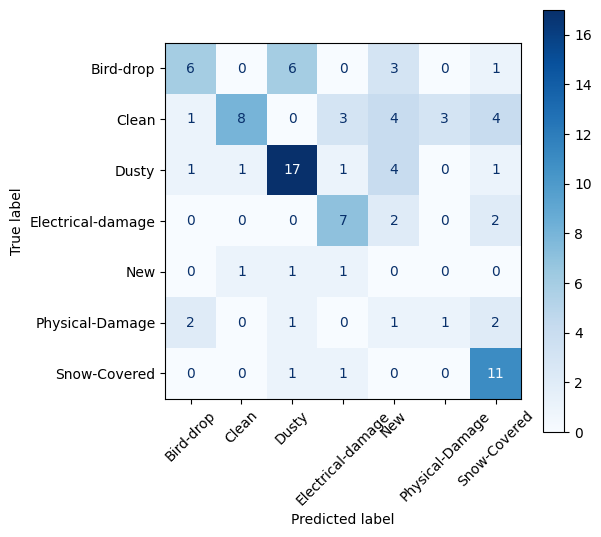

In [14]:
p_test, y_test = predict(model, test_dl)
pred = p_test.argmax(1)
labels_all = list(range(len(classes)))
print(classification_report(y_test, pred, labels=labels_all, target_names=classes,
                            digits=3, zero_division=0))
print('Macro-F1:', round(f1_score(y_test, pred, average='macro'), 3))
fig, ax = plt.subplots(figsize=(max(6, 0.9 * len(classes)), max(5, 0.8 * len(classes))))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=labels_all),
                       display_labels=classes).plot(cmap='Blues', ax=ax,
                                                    xticks_rotation=45)
plt.tight_layout()
plt.show()


### Results and calculations

| Class | Precision | Recall | F1 | Support |
|---|---|---|---|---|
| Bird-drop | 0.600 | 0.375 | 0.462 | 16 |
| Clean | 0.800 | 0.348 | 0.485 | 23 |
| Dusty | 0.654 | 0.680 | 0.667 | 25 |
| Electrical-damage | 0.538 | 0.636 | 0.583 | 11 |
| **New** | 0.000 | 0.000 | **0.000** | 3 |
| Physical-Damage | 0.250 | 0.143 | 0.182 | 7 |
| Snow-Covered | 0.524 | 0.846 | 0.647 | 13 |

**Worked examples from the confusion matrix** (row = true class, column = predicted):

* Bird-drop: $TP=6$, $FN=16-6=10$, $FP=10-6=4$ (column sum 10) → $P=6/10=0.600$, $R=6/16=0.375$, $F1=\dfrac{2(0.600)(0.375)}{0.975}=0.462$ ✔
* Dusty: $TP=17$, column sum $26$ → $P=17/26=0.654$; row sum $25$ → $R=17/25=0.680$.
* New: the model **predicted `New` 14 times** (column sum $3+4+4+2+0+1+0$) but **never correctly** → $P=0/14=0$ and $R=0/3=0$.

**Averages**

$$\text{Accuracy}=\frac{6+8+17+7+0+1+11}{98}=\frac{50}{98}=\mathbf{0.510}$$

$$\text{Macro-F1}=\frac{0.462+0.485+0.667+0.583+0+0.182+0.647}{7}=\frac{3.026}{7}=\mathbf{0.432}$$

$$\text{Weighted-F1}=\frac{16(0.462)+23(0.485)+25(0.667)+11(0.583)+3(0)+7(0.182)+13(0.647)}{98}=\mathbf{0.524}$$

* **Macro 0.432 < weighted 0.524** (gap 0.092): the weighted score is lifted by the big classes (Dusty, Clean), while the zero-F1 `New` class barely affects it ($3/98 = 3\%$ weight) – the exact situation slide 23 warns about.
* Macro precision $=0.481$, macro recall $=0.433$.
* Baselines: random guessing $=1/7=14.3\%$; always predicting the majority class (Dusty) $=25/98=25.5\%$. The model's 51.0 % is better than both, but far from a usable inspector.
* **Val vs test:** best val macro-F1 0.477 vs test 0.432 (gap 0.045). The best epoch was *selected on val*, so val is optimistically biased; test is the honest number.

**Biggest confusions (from the matrix):** Bird-drop → Dusty (6) and Bird-drop → New (3); Clean → New (4), Snow-Covered (4), Electrical-damage (3), Physical-Damage (3); Dusty → New (4). Soiling classes (bird-drop, dust, "new" with dirt) look alike; "Clean" images are scattered everywhere (recall 8/23).

## Task 5.2 – Binary threshold analysis (skipped) → per-class recall instead

**What it does.** The sensitivity/threshold/PPV block is for 2-class problems only. With 7 classes the cell prints **per-class recall** (= per-class sensitivity) and accuracy.

$$\text{Sensitivity}_c=\frac{TP_c}{TP_c+FN_c},\qquad \text{Specificity}_c=\frac{TN_c}{TN_c+FP_c},\qquad
\text{PPV}_c=\frac{\text{sens}\cdot\text{prev}}{\text{sens}\cdot\text{prev}+(1-\text{spec})(1-\text{prev})}$$

(For a multi-class model I compute these **one-vs-rest** from the confusion matrix, in the markdown cell below the code.)

In [15]:
if len(classes) == 2:
    pos = classes.index(POSITIVE)
    p_val, y_val = predict(model, val_dl)
    fpr, tpr, thr = roc_curve(y_val == pos, p_val[:, pos])
    t = thr[np.argmax(tpr >= TARGET_RECALL)]     # highest t reaching target
    print(f'Threshold chosen on VALIDATION for recall >= {TARGET_RECALL}: '
          f'{t:.3f}')

    s = p_test[:, pos]
    yp, yt = s >= t, y_test == pos
    tp, fn = (yp & yt).sum(), (~yp & yt).sum()
    tn, fp = (~yp & ~yt).sum(), (yp & ~yt).sum()
    print(f'TP {tp} | FN {fn} | TN {tn} | FP {fp}')
    print(f'Test prevalence of {POSITIVE}: {yt.mean():.3f}')
    print(f'Test AUC {roc_auc_score(yt, s):.3f}')
    print(f'Sensitivity {tp / (tp + fn):.3f}   Specificity {tn / (tn + fp):.3f}'
          f'   PPV {tp / max(tp + fp, 1):.3f}')
else:
    # Threshold / sensitivity analysis only makes sense for a 2-class problem.
    # For this multi-class dataset report per-class recall (= sensitivity of each class) instead.
    cm = confusion_matrix(y_test, pred, labels=list(range(len(classes))))
    recall = cm.diagonal() / np.maximum(cm.sum(1), 1)
    print('Binary threshold analysis skipped (more than 2 classes). Per-class recall on test:')
    print(pd.Series(recall, index=classes).round(3).to_string())
    print('Test accuracy:', round((pred == y_test).mean(), 3))


Binary threshold analysis skipped (more than 2 classes). Per-class recall on test:
Bird-drop            0.375
Clean                0.348
Dusty                0.680
Electrical-damage    0.636
New                  0.000
Physical-Damage      0.143
Snow-Covered         0.846
Test accuracy: 0.51


### Results and calculations

Printed per-class recall: Bird-drop 0.375, Clean 0.348, Dusty 0.680, Electrical-damage 0.636, **New 0.000**, Physical-Damage 0.143, Snow-Covered 0.846; test accuracy 0.510.

**One-vs-rest table from the confusion matrix** ($N=98$; $TN=N-TP-FN-FP$):

| Class | TP | FN | FP | TN | Sensitivity | Specificity | Test prevalence | PPV at test prevalence | PPV at 5 % prevalence |
|---|---|---|---|---|---|---|---|---|---|
| Bird-drop | 6 | 10 | 4 | 78 | 0.375 | 0.951 | 0.163 | 0.600 | 0.288 |
| Clean | 8 | 15 | 2 | 73 | 0.348 | 0.973 | 0.235 | 0.800 | 0.407 |
| Dusty | 17 | 8 | 9 | 64 | 0.680 | 0.877 | 0.255 | 0.654 | 0.225 |
| Electrical-damage | 7 | 4 | 6 | 81 | 0.636 | 0.931 | 0.112 | 0.538 | 0.327 |
| New | 0 | 3 | 14 | 81 | 0.000 | 0.853 | 0.031 | 0 (no TP) | 0 (no TP) |
| Physical-Damage | 1 | 6 | 3 | 88 | 0.143 | 0.967 | 0.071 | 0.250 | 0.186 |
| Snow-Covered | 11 | 2 | 10 | 75 | 0.846 | 0.882 | 0.133 | 0.524 | 0.275 |

**Hand calculation of PPV (Dusty, sens = 0.680, spec = 0.877):**

* At the test prevalence 25/98 = 0.255: $\text{PPV}=\dfrac{0.680(0.255)}{0.680(0.255)+0.123(0.745)}=\dfrac{0.1734}{0.1734+0.0916}=\mathbf{0.654}$ (equals the table's precision 17/26 ✔).
* At 5 % prevalence: $\text{PPV}=\dfrac{0.680(0.05)}{0.680(0.05)+0.123(0.95)}=\dfrac{0.0340}{0.0340+0.1169}=\mathbf{0.225}$.

So if only 5 % of panels were actually dusty, **more than three out of four "dusty" alerts would be false alarms** with this model. (The 5 % value is an *illustrative* prevalence – the real prevalence of each fault at a given solar farm must be measured.)

> ### ✍️ Write it – Part 5
> **Macro-F1 = 0.432; weakest class = `New`** (recall 0/3, F1 0.000; 14 false `New` predictions), followed by Physical-Damage (F1 0.182, recall 1/7). Accuracy is 0.510 and weighted-F1 0.524 – both look better than macro-F1 because the large classes dominate. **Binary threshold/PPV analysis is not applicable** (7 classes); per-class sensitivity/specificity are in the table above. **PPV difference in plain language:** PPV answers "when the model raises an alarm for this fault, how often is it right?" – it depends on how common the fault is. At the test-set mix (e.g. Dusty ≈ 25 % of images) a Dusty alarm is right 65 % of the time; if Dusty were only 5 % of real panels, the same model would be right only 22.5 % of the time, because the many healthy panels generate many more false alarms than the few dusty ones generate true alarms. **Safety-critical classes (Electrical-damage, Physical-Damage) have the lowest or noisiest numbers (recall 0.636 / 0.143), so the model must not be used to clear panels as healthy.**

---
# Part 6 – Grad-CAM shortcut check

## Task 6.1 – Grad-CAM class and the first six heatmaps

**Method (slide 29, Selvaraju et al. 2017).** For a target class $c$ and the last convolutional block (`layer4`, **512 feature maps of 7 × 7** for a 224 × 224 input, since $224/32=7$):

$$\alpha_k^{c}=\frac{1}{Z}\sum_{i}\sum_{j}\frac{\partial y^{c}}{\partial A^{k}_{ij}},\qquad
L^{c}_{\text{Grad-CAM}}=\operatorname{ReLU}\Bigl(\sum_{k}\alpha_k^{c}A^{k}\Bigr)$$

with $Z=7\times7=49$. The code (1) hooks the forward activations $A^k$ and the backward gradients, (2) averages gradients over space to get $\alpha_k$, (3) takes the ReLU of the weighted sum, (4) up-samples $7\times7\to224\times224$ (×32, bilinear), and (5) divides by the maximum so heat ∈ [0, 1] (red = pushed the score toward the predicted class).

**Selection of images:** first 3 correct and first 3 wrong test predictions. Because `test_df` is sorted by class, the first indices are all **Bird-drop** (Bird-drop is class 0) – this is why the next cell re-samples across classes.

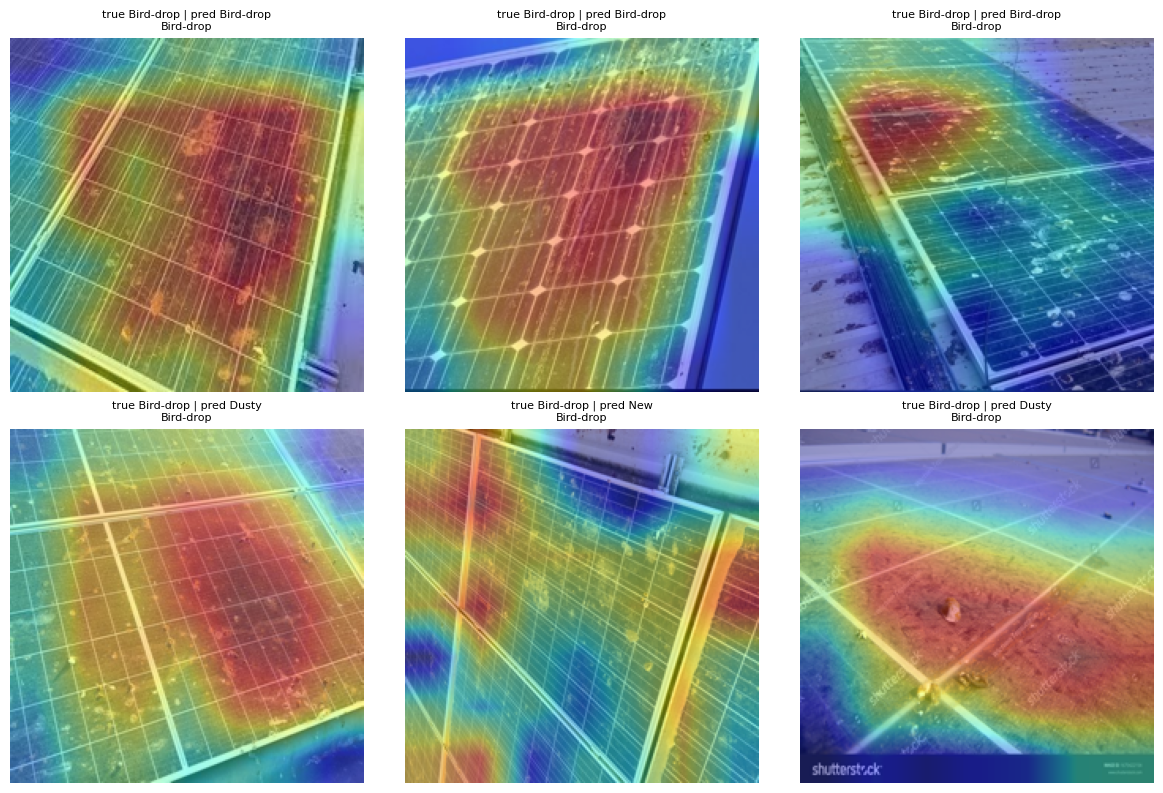

In [16]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        layer.register_forward_hook(self._save_act)
        layer.register_full_backward_hook(self._save_grad)
    def _save_act(self, m, i, o):
        self.acts = o.detach()
    def _save_grad(self, m, gi, go):
        self.grads = go[0].detach()
    def __call__(self, x, cls=None):
        self.model.eval()
        x = x.unsqueeze(0).to(device).requires_grad_(True)
        logits = self.model(x)
        cls = int(logits.argmax()) if cls is None else cls
        self.model.zero_grad()
        logits[0, cls].backward()
        alpha = self.grads.mean(dim=(2, 3), keepdim=True)      # (1/Z) sum dy/dA
        cam = F.relu((alpha * self.acts).sum(1)).squeeze()     # ReLU(sum a*A)
        cam = F.interpolate(cam[None, None], size=x.shape[-2:],
                            mode='bilinear').squeeze()
        return (cam / (cam.max() + 1e-8)).cpu().numpy(), cls

for p in model.parameters():
    p.requires_grad = True
cam = GradCAM(model, last_block)
wrong = np.where(pred != y_test)[0][:3].tolist()
right = np.where(pred == y_test)[0][:3].tolist()
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, i in zip(axes.flat, right + wrong):
    x, y = test_ds[i]
    heat, c = cam(x)
    img = Image.open(test_ds.paths[i]).convert('RGB').resize((IMG_SIZE,) * 2)
    ax.imshow(img)
    ax.imshow(heat, cmap='jet', alpha=0.4)
    ax.set_title(f'true {classes[y]} | pred {classes[c]}\n{test_df.orig_class[i]}', fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

### Results – the six heatmaps (all true class = Bird-drop)

| # | Result | Where the model looked | Legitimate evidence? |
|---|---|---|---|
| 1 | true Bird-drop → **Bird-drop** ✔ | Large hot region over the soiled middle of the panel, where droppings/dirt are | **Yes** |
| 2 | true Bird-drop → **Bird-drop** ✔ | Broad heat over the central panel surface, dark-blue frame/background cold | Mostly yes (diffuse; not tied to individual droppings) |
| 3 | true Bird-drop → **Bird-drop** ✔ | Hot area at the upper-left soiled part near the roof/frame; the cleaner lower-right panel is cold | **Yes** (focuses on the dirty area) |
| 4 | true Bird-drop → **Dusty** ✘ | Whole panel surface hot (evenly spread) | Reasonable – uniform soiling is read as dust |
| 5 | true Bird-drop → **New** ✘ | Scattered weak heat on frame edges and left/right borders, little on droppings | **No** – edge/frame cues, not the damage |
| 6 | true Bird-drop → **Dusty** ✘ | Heat on the dirty ground/panel surface near the dropping, with some spill toward the stock-photo watermark band | Partly; watermark nearby is a warning sign |

## Task 6.2 – Heatmaps across classes (one correct example per class + 4 mistakes)

**What it does.** Chooses **one correctly classified test image per original folder** plus up to **4 random mistakes**, to avoid the class-0 bias of the previous cell. Total $6\text{ right}+4\text{ wrong}=10$ heatmaps (the figure has 10 populated panels: the 6 correct classes that had a correct example – *New* has none – plus 4 errors).

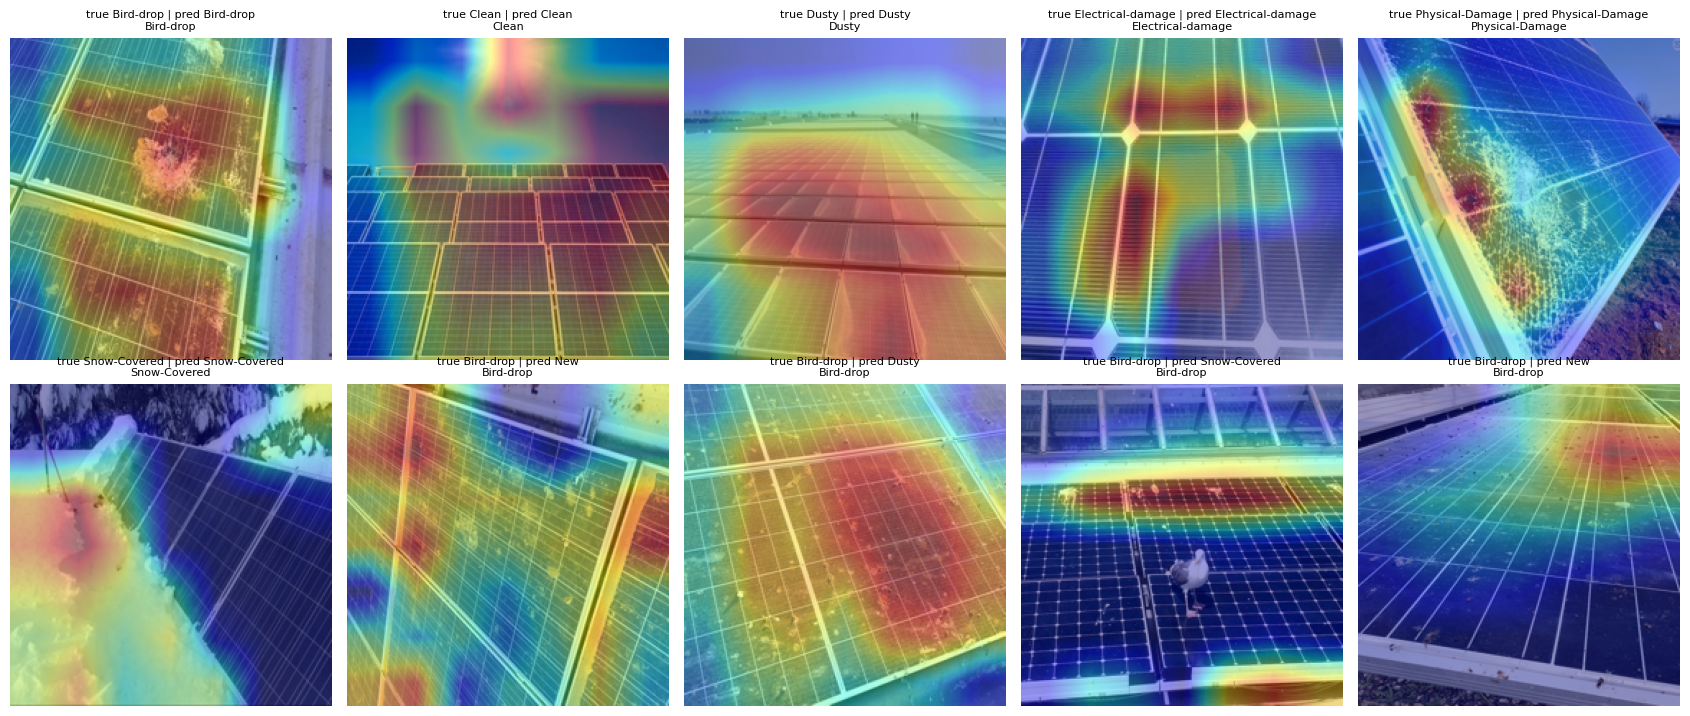

In [17]:
rng = np.random.default_rng(0)
orig = test_df['orig_class'].values
right_pool = np.where(pred == y_test)[0]
wrong_pool = np.where(pred != y_test)[0]
# one correctly classified example per original folder, plus up to 4 mistakes
right = [int(rng.choice(right_pool[orig[right_pool] == c]))
         for c in sorted(set(orig)) if (orig[right_pool] == c).any()]
wrong = rng.choice(wrong_pool, size=min(4, len(wrong_pool)), replace=False).tolist()
idx = right + wrong

ncols = 5
nrows = int(np.ceil(len(idx) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.4 * ncols, 3.6 * nrows))
axes = np.atleast_2d(axes)
for ax in axes.flat:
    ax.axis('off')
for ax, i in zip(axes.flat, idx):
    x, y = test_ds[i]
    heat, c = cam(x)
    img = Image.open(test_ds.paths[i]).convert('RGB').resize((IMG_SIZE,) * 2)
    ax.imshow(img)
    ax.imshow(heat, cmap='jet', alpha=0.4)
    ax.set_title(f'true {classes[y]} | pred {classes[c]}\n{test_df.orig_class[i]}', fontsize=8)
plt.tight_layout()
plt.show()


### Results – ten heatmaps read one by one

| # | True → Predicted | Where the model looked | Evidence or shortcut? |
|---|---|---|---|
| 1 | Bird-drop → Bird-drop ✔ | Red on the soiled patch of the panel (droppings) | **Evidence** |
| 2 | Clean → Clean ✔ | Hottest region is the **sky above the panels** (top-centre), panels only moderately warm | ⚠️ **Shortcut suspect** (background/sky) |
| 3 | Dusty → Dusty ✔ | Panel field in the lower half; horizon/sky weakly warm | Mostly evidence (panel surface) |
| 4 | Electrical-damage → Electrical-damage ✔ | Heat on the panel cells/busbar junctions where the damage lies | **Evidence** |
| 5 | Physical-Damage → Physical-Damage ✔ | Heat along the cracked/shattered left region | **Evidence** |
| 6 | Snow-Covered → Snow-Covered ✔ | Heat on the snow on the left | **Evidence** (snow *is* the class) |
| 7 | Bird-drop → **New** ✘ | Diffuse patches over the panel and frame | Weak / unclear |
| 8 | Bird-drop → **Dusty** ✘ | Whole soiled panel surface | Plausible confusion (dust vs. droppings) |
| 9 | Bird-drop → **Snow-Covered** ✘ | Heat on a horizontal band at the top of the array and at the bottom edge – **not** on the bird standing on the panel | ⚠️ **Shortcut-like** (background/edge, ignores the real evidence) |
| 10 | Bird-drop → **New** ✘ | Top-right sky/roof edge | ⚠️ **Not evidence** |

**Overall verdict: SHORTCUT SUSPECTED (not confirmed).** The correct *damage* classes (Electrical, Physical, Bird-drop, Snow) are mostly explained by the right regions, but (a) `Clean` is partly explained by the **sky**, (b) several errors are driven by **edges/background**, and (c) stock-photo **watermarks** appear in the data and sometimes near hot regions.

**Experiments to test it**

1. **Mask or crop the sky/background** (keep only the panel region) for all `Clean` and `Snow-Covered` test images and re-score: if `Clean` recall (now 8/23 = 0.348) collapses, sky was the cue.
2. **Paint out watermark/logo areas** on the test images that have them and compare predictions before/after.
3. **Occlusion test:** slide a grey patch over the hottest region and measure the drop in the class probability $\Delta p=p_{\text{orig}}-p_{\text{occluded}}$.
4. **External test:** evaluate on photos taken by yourself on a different roof/camera (the strongest defence against shortcuts, slide 10).

> **Caution:** Grad-CAM is coarse (7 × 7 up-sampled to 224 × 224, each cell covers 32 × 32 px) and this network was trained from scratch on 551 images, so use the maps to detect *suspicious* behaviour, not to localise faults.

> ### ✍️ Write it – Part 6
> The one-line readings for all six (first figure) and ten (second figure) heatmaps are in the two tables above. **Verdict: shortcut suspected** – `Clean` predictions rely partly on the sky, some mistakes follow frames/edges instead of the bird or dirt, and some images carry watermarks. Follow-up: crop out the sky and the watermark regions and re-score; if macro-F1 or `Clean` recall drops sharply the model was using context rather than panel condition.

---
# Part 7 – Save the model and document

## Task 7.1 – Save the checkpoint

Stores the weights together with everything needed to reload the model (`classes`, `backbone`, `img_size`, `grayscale`) in `/kaggle/working/week6_model.pt`.

$$\text{size}\approx 11.18\text{ M parameters}\times 4\text{ bytes}\approx 44.7\text{ MB (float32)}$$

In [18]:
torch.save({'state_dict': model.state_dict(), 'classes': classes,
            'backbone': BACKBONE, 'img_size': IMG_SIZE,
            'grayscale': GRAYSCALE}, '/kaggle/working/week6_model.pt')
print('Saved week6_model.pt')

Saved week6_model.pt


Output: `Saved week6_model.pt` ✔. Reload with `torch.load(path)['state_dict']` after rebuilding `resnet18` with a 7-way `fc`. Note that this checkpoint is the **epoch-10, from-scratch** model.

---
# Check Your Understanding – answers with working

**1. Why does a random split of chest X-rays overestimate performance?**
One child has several X-rays, and images of the same patient are highly correlated (same body, scanner, markers). A random split puts some in train and some in test, so the model can match a test X-ray to the same child's training X-ray (memorisation / shortcut) instead of learning pneumonia. The test score then looks too good and fails on new patients. *In this notebook the same effect appeared as duplicates:* 12/110 = 10.9 % of test images had a near-copy in train.

**2. Two classes with 900 and 100 images: class weights** ($N=1000$, $K=2$)

$$w_{900}=\frac{1000}{2\times900}=0.556,\qquad w_{100}=\frac{1000}{2\times100}=5.0$$

Check: $900\times0.556=500$ and $100\times5.0=500$ → equal total weight ✔.

**3. Focal loss, $\gamma=2$, $p_t=0.8$**

$$(1-p_t)^\gamma=(1-0.8)^2=0.2^2=0.04=\tfrac{1}{25}$$

The example is **down-weighted 25-fold** (its loss is multiplied by 0.04).

**4. Sensitivity 0.90, specificity 0.95, prevalence 2 %**

$$\text{PPV}=\frac{0.90(0.02)}{0.90(0.02)+(1-0.95)(1-0.02)}=\frac{0.018}{0.018+0.049}=\frac{0.018}{0.067}=\mathbf{0.269}$$

Per 1,000 people: 18 true positives and 49 false positives → only ≈ 27 % of positive flags are real.

**5. When is macro-F1 better than weighted F1?**
When classes are imbalanced **and every class matters equally** (rare faults, rare diseases). Weighted-F1 is dominated by large classes. This notebook: weighted-F1 = 0.524 hides that `New` has F1 = 0 (weight 3/98), whereas macro-F1 = 0.432 exposes it.

**6. Grad-CAM highlights a hospital label in the corner. What next?**
Treat it as a **shortcut**: (i) confirm on more correct *and* wrong cases; (ii) test by masking/cropping the corner and re-scoring – a large drop confirms it; (iii) remove or mask markers in **all** splits, or crop to the lung field, and retrain; (iv) validate on images from another hospital before trusting any metric; (v) report the finding in the README. (Here the analogue is the watermark/sky issue.)